# CS770 — Visual Quality Inspection

**Team Members:** David Jantz, Dheeksha Mani, Rachael Parker

### Dataset & Source Attribution
- **Dataset:** *Casting Product Image Data for Quality Inspection* by Ravirajsinh Dabhi (Kaggle)
- **Collection Used:** The 1,300 original 512 x 512 photographs in casting_512x512 (ok_front and def_front).

### Data Placement & Running from a Fresh Session
1. **Environment Setup:** Create/activate a Python virtual environment and install pinned dependencies:
   ```bash
   pip install -r requirements.txt
   ```
2. **Data Placement:** Download and extract the Kaggle archive, then place `casting_512x512` alongside this notebook (`./casting_512x512`).
3. **Execution:** From Jupyter / VS Code, choose **Restart Kernel and Run All Cells** to execute the full pipeline in order.

### AI-Assistance Disclosure
Generative AI tools were used to assist with code debugging, notebook organization and auditing, and plot formatting fixes. All experimental design decisions, model runs, and written analyses were reviewed and verified by the team.

## 1. Data Preparation

### Setup, Random Seed (770) & Label Definitions

In [ ]:
import hashlib
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset
from IPython.display import display

SEED = 770
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ACCEPTABLE = 0
DEFECTIVE = 1
LABEL_MAP = {"ok_front": ACCEPTABLE, "def_front": DEFECTIVE}
CLASS_NAMES = {ACCEPTABLE: "acceptable", DEFECTIVE: "defective"}

DATA_DIR = Path(os.environ.get("CASTING_DATA_DIR", "casting_512x512"))


def find_class_dir(base_dir: Path, name: str) -> Path:
    matches = sorted(
        p for p in base_dir.rglob(name)
        if p.is_dir() and "casting_data" not in {part.lower() for part in p.parts}
    )
    if not matches:
        raise FileNotFoundError(f"Missing '{name}' under '{base_dir.name}'.")
    return matches[0]


ok_dir = find_class_dir(DATA_DIR, "ok_front")
def_dir = find_class_dir(DATA_DIR, "def_front")
print(f"Labels: defective = {DEFECTIVE}, acceptable = {ACCEPTABLE} | Random seed = {SEED}")


Labels: defective = 1, acceptable = 0 | Random seed = 770


### Data Audit: Dimensions, Class Counts & Exclusions


In [ ]:
records, unreadable = [], []

for folder_name, folder_path in [("ok_front", ok_dir), ("def_front", def_dir)]:
    label = LABEL_MAP[folder_name]
    for p in sorted(folder_path.iterdir()):
        if not p.is_file():
            continue
        rel_path = f"{folder_name}/{p.name}"
        try:
            with Image.open(p) as im:
                im.load()
                dims = f"{im.size[0]} x {im.size[1]}"
                arr = np.asarray(im)
                pix_hash = hashlib.sha256(arr.tobytes() + str(arr.shape).encode()).hexdigest()
            records.append(
                {
                    "label": label,
                    "class": CLASS_NAMES[label],
                    "filename": p.name,
                    "rel_path": rel_path,
                    "path": p,
                    "dimensions": dims,
                    "pixel_sha256": pix_hash,
                }
            )
        except Exception as exc:
            unreadable.append(f"{rel_path} ({type(exc).__name__})")

raw_df = pd.DataFrame(records).sort_values(["label", "filename"]).reset_index(drop=True)

kept_idx, same_label_dups, conflicting_dups = [], [], []
for _, grp in raw_df.groupby("pixel_sha256", sort=False):
    grp_sorted = grp.sort_values(["label", "filename"])
    if grp_sorted["label"].nunique() > 1:
        conflicting_dups.extend(grp_sorted["rel_path"].tolist())
    else:
        kept_idx.append(grp_sorted.index[0])
        same_label_dups.extend(grp_sorted["rel_path"].iloc[1:].tolist())

cleaned_df = raw_df.loc[kept_idx].sort_values(["label", "filename"]).reset_index(drop=True)

audit_df = pd.DataFrame(
    [
        {
            "Class": f"{CLASS_NAMES[lbl]} ({lbl})",
            "Count": int((cleaned_df["label"] == lbl).sum()),
            "Dimensions": ", ".join(sorted(cleaned_df.loc[cleaned_df["label"] == lbl, "dimensions"].unique())),
        }
        for lbl in [ACCEPTABLE, DEFECTIVE]
    ]
    + [
        {
            "Class": "Total",
            "Count": len(cleaned_df),
            "Dimensions": ", ".join(sorted(cleaned_df["dimensions"].unique())),
        }
    ]
)
display(audit_df)

total_excluded = len(unreadable) + len(same_label_dups) + len(conflicting_dups)
print(
    f"Exclusions -> unreadable: {len(unreadable)}, same-label duplicates: {len(same_label_dups)}, "
    f"conflicting-label duplicates: {len(conflicting_dups)}, total excluded: {total_excluded}."
)
if unreadable:
    print("Unreadable:", unreadable)
if same_label_dups:
    print("Excluded same-label duplicates:", same_label_dups)
if conflicting_dups:
    print("Set-aside conflicting-label duplicates:", conflicting_dups)


,Class,Count,Dimensions
0,acceptable (0),519,512 x 512
1,defective (1),781,512 x 512
2,Total,1300,512 x 512


Exclusions -> unreadable: 0, same-label duplicates: 0, conflicting-label duplicates: 0, total excluded: 0.


### Labeled Grid of 8 Sample Images


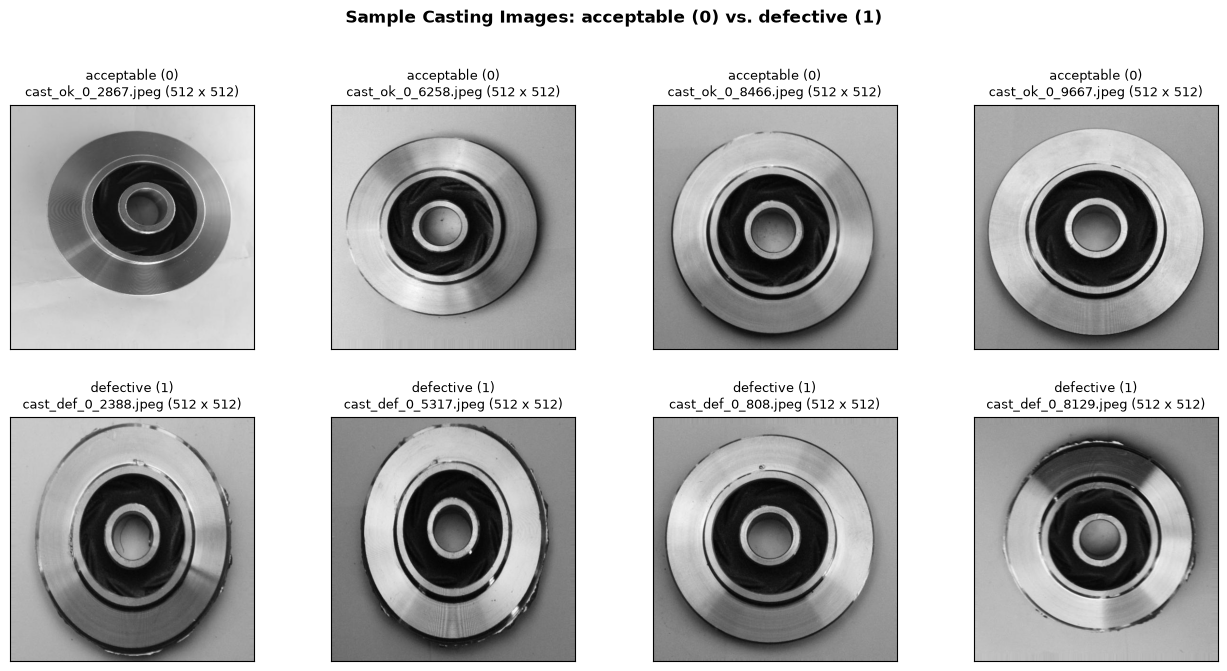

In [ ]:
rng = np.random.default_rng(SEED)
sample_rows = []
for lbl in [ACCEPTABLE, DEFECTIVE]:
    idx = sorted(rng.choice(cleaned_df[cleaned_df["label"] == lbl].index.to_numpy(), size=4, replace=False))
    sample_rows.extend(cleaned_df.loc[i] for i in idx)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for ax, row in zip(axes.flat, sample_rows):
    with Image.open(row["path"]) as im:
        ax.imshow(im)
    ax.set_title(f"{row['class']} ({row['label']})\n{row['filename']} ({row['dimensions']})", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Sample Casting Images: acceptable (0) vs. defective (1)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.subplots_adjust(hspace=0.28)
plt.show()


### Stratified Train / Validation / Test Split (70% / 15% / 15%, Seed 770)


In [ ]:
train_df, temp_df = train_test_split(
    cleaned_df, test_size=0.30, stratify=cleaned_df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)
train_df, val_df, test_df = (
    train_df.reset_index(drop=True),
    val_df.reset_index(drop=True),
    test_df.reset_index(drop=True),
)

splits = [("Train", train_df), ("Validation", val_df), ("Test", test_df)]
split_table = pd.DataFrame(
    [
        {
            "Split": name,
            "Total": len(df_s),
            "Share": f"{100.0 * len(df_s) / len(cleaned_df):.1f}%",
            "acceptable (0)": int((df_s["label"] == ACCEPTABLE).sum()),
            "defective (1)": int((df_s["label"] == DEFECTIVE).sum()),
        }
        for name, df_s in splits
    ]
)
display(split_table)

for name, df_s in splits:
    files = sorted(df_s["rel_path"].tolist())
    print(f"\n{name.upper()} ({len(files)} images):")
    for i in range(0, len(files), 5):
        print("  " + "  ".join(f"{f:<30}" for f in files[i : i + 5]).rstrip())


,Split,Total,Share,acceptable (0),defective (1)
0,Train,910,70.0%,363,547
1,Validation,195,15.0%,78,117
2,Test,195,15.0%,78,117



TRAIN (910 images):
  def_front/cast_def_0_0.jpeg     def_front/cast_def_0_1015.jpeg  def_front/cast_def_0_102.jpeg   def_front/cast_def_0_1053.jpeg  def_front/cast_def_0_1055.jpeg
  def_front/cast_def_0_1087.jpeg  def_front/cast_def_0_1091.jpeg  def_front/cast_def_0_1112.jpeg  def_front/cast_def_0_1115.jpeg  def_front/cast_def_0_1123.jpeg
  def_front/cast_def_0_1137.jpeg  def_front/cast_def_0_1139.jpeg  def_front/cast_def_0_1145.jpeg  def_front/cast_def_0_1147.jpeg  def_front/cast_def_0_1155.jpeg
  def_front/cast_def_0_1157.jpeg  def_front/cast_def_0_1187.jpeg  def_front/cast_def_0_1188.jpeg  def_front/cast_def_0_1225.jpeg  def_front/cast_def_0_1226.jpeg
  def_front/cast_def_0_1257.jpeg  def_front/cast_def_0_1261.jpeg  def_front/cast_def_0_127.jpeg   def_front/cast_def_0_1283.jpeg  def_front/cast_def_0_1286.jpeg
  def_front/cast_def_0_1359.jpeg  def_front/cast_def_0_1381.jpeg  def_front/cast_def_0_1411.jpeg  def_front/cast_def_0_1427.jpeg  def_front/cast_def_0_1432.jpeg
  def_front/c

### Grayscale 64 x 64 Preprocessing Scaled to [0, 1]


In [ ]:
IMG_SIZE = (64, 64)


def preprocess_image(path: Path) -> np.ndarray:
    with Image.open(path) as im:
        gray = im.convert("L").resize(IMG_SIZE, Image.Resampling.BILINEAR)
        return np.asarray(gray, dtype=np.float32) / 255.0


def build_arrays(df_s: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    X = np.stack([preprocess_image(p) for p in df_s["path"]], axis=0)
    y = df_s["label"].to_numpy(dtype=np.int64, copy=True)
    return X, y


X_train, y_train = build_arrays(train_df)
X_val, y_val = build_arrays(val_df)
X_test, y_test = build_arrays(test_df)

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

train_dataset = TensorDataset(torch.from_numpy(X_train).unsqueeze(1), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val).unsqueeze(1), torch.from_numpy(y_val))
test_dataset = TensorDataset(torch.from_numpy(X_test).unsqueeze(1), torch.from_numpy(y_test))

prep_table = pd.DataFrame(
    [
        {
            "Split": name,
            "Image": str(X.shape),
            "Flat": str(X_flat.shape),
            "Tensor": str(tuple(ds.tensors[0].shape)),
            "Dtype": str(X.dtype),
            "Min": f"{X.min():.4f}",
            "Max": f"{X.max():.4f}",
        }
        for name, X, X_flat, ds in [
            ("Train", X_train, X_train_flat, train_dataset),
            ("Validation", X_val, X_val_flat, val_dataset),
            ("Test", X_test, X_test_flat, test_dataset),
        ]
    ]
)
display(prep_table)


,Split,Image,Flat,Tensor,Dtype,Min,Max
0,Train,"(910, 64, 64)","(910, 4096)","(910, 1, 64, 64)",float32,0.0235,1.0000
1,Validation,"(195, 64, 64)","(195, 4096)","(195, 1, 64, 64)",float32,0.0235,1.0000
2,Test,"(195, 64, 64)","(195, 4096)","(195, 1, 64, 64)",float32,0.0275,1.0000


## 2. Baseline Model (Logistic Regression)

### Setup and Helpers

In [ ]:
import platform, sys, time, copy, warnings
import sklearn
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__} | device {DEVICE} | seed {SEED}")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def defect_metrics(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
    }

THRESHOLD = 0.5  # fixed decision rule: P(defective) >= 0.5 -> defective

Python 3.14.5 | numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0+cpu | device cpu | seed 770


### Baseline (Logistic Regression)

In [ ]:
set_seed()
log_reg = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEED)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    t0 = time.perf_counter()
    log_reg.fit(X_train_flat, y_train)
    lr_train_time = time.perf_counter() - t0

conv = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
print("Settings:", log_reg.get_params())
print(f"Iterations: {int(log_reg.n_iter_[0])}/{log_reg.max_iter} | time {lr_train_time:.2f}s")
print("Convergence issue:", conv[0].splitlines()[0] if conv else "none")

lr_val_pred = (log_reg.predict_proba(X_val_flat)[:, 1] >= THRESHOLD).astype(int)
lr_val_metrics = defect_metrics(y_val, lr_val_pred)
print({k: round(v, 4) for k, v in lr_val_metrics.items()})

Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 770, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Iterations: 501/1000 | time 1.56s
Convergence issue: none
{'Precision': 0.8696, 'Recall': 0.8547, 'F1': 0.8621, 'Accuracy': 0.8359}


### Baseline Settings and Convergence
Logistic regression (`C=1.0`, L2 regularization, `solver="lbfgs"`, `max_iter=1000`, `random_state=770`) was trained on the 4,096 flattened grayscale pixels scaled to `[0, 1]`. It converged in `501` of `1000` iterations with convergence issue `none`, in `1.56 s`, achieving validation Precision `0.8696`, Recall `0.8547`, F1 `0.8621`, and Accuracy `0.8359`.

## 3. Small PyTorch CNN (CNN-A)

### CNN Design Choices
- **Architecture:** Three blocks of `Conv2d` (3x3, padding 1) + `ReLU` + `MaxPool2d(2)` (16, 32, and 64 filters), followed by `Flatten`, a 128-unit linear layer with `ReLU`, `Dropout` (`p = 0.0` for baseline CNN-A), and a 1-logit output. Small enough to train quickly on CPU while deep enough to capture local casting textures, rims, and surface defects.
- **Loss:** `BCEWithLogitsLoss`, appropriate for binary classification (`acceptable = 0`, `defective = 1`) with one raw logit output.
- **Optimizer:** `Adam` with learning rate `1e-3`, a reliable default requiring minimal tuning.
- **Batch size:** `32`, light on memory and giving ~29 gradient updates per epoch across 910 training images.
- **Training duration:** `15` epochs; the checkpoint with the lowest validation loss is retained.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64))   # 64 -> 32 -> 16 -> 8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 1)
        )
    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

BATCH_SIZE, EPOCHS, LR = 32, 15, 1e-3

@torch.no_grad()
def predict_probs(model, dataset):
    model.eval()
    loader = DataLoader(dataset, batch_size=128, shuffle=False)
    return torch.cat([torch.sigmoid(model(xb.to(DEVICE))).cpu() for xb, _ in loader]).numpy()

def train_cnn(dropout, lr=LR, epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED):
    set_seed(seed)
    model = SmallCNN(dropout=dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=g)
    val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

    hist = {"train_loss": [], "val_loss": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.float().to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        model.eval(); vt, vn = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                vt += loss_fn(model(xb.to(DEVICE)), yb.float().to(DEVICE)).item() * len(xb); vn += len(xb)
        hist["train_loss"].append(tot / n); hist["val_loss"].append(vt / vn)
        if hist["val_loss"][-1] < best_val:
            best_val, best_epoch = hist["val_loss"][-1], epoch
            best_state = copy.deepcopy(model.state_dict())
    elapsed = time.perf_counter() - t0
    model.load_state_dict(best_state)
    return model, hist, best_epoch, elapsed

cnn_a, hist_a, best_ep_a, time_a = train_cnn(dropout=0.0)
val_metrics_a = defect_metrics(y_val, (predict_probs(cnn_a, val_dataset) >= THRESHOLD).astype(int))
print(f"CNN-A (dropout 0.0): best epoch {best_ep_a}, time {time_a:.1f}s")
print({k: round(v, 4) for k, v in val_metrics_a.items()})

CNN-A (dropout 0.0): best epoch 15, time 23.6s
{'Precision': 0.9252, 'Recall': 0.8462, 'F1': 0.8839, 'Accuracy': 0.8667}


In [ ]:
print("Train loss, last epoch:     ", round(hist_a["train_loss"][-1], 4))
print("Validation loss, last epoch:", round(hist_a["val_loss"][-1], 4))
print("Best validation loss:       ", round(min(hist_a["val_loss"]), 4))

Train loss, last epoch:      0.2178
Validation loss, last epoch: 0.3284
Best validation loss:        0.3284


## 4. Controlled Experiment (CNN-B: Dropout 0.0 vs. 0.5)

### Expectation Before Running CNN-B
**Expectation for the controlled experiment (dropout 0.0 vs 0.5):** CNN-A reached a training loss of `0.2178` against a validation loss of `0.3284` (gap `0.1106`), and validation loss reached its lowest value at epoch `15`, so the model has not yet clearly overfit within the 15-epoch budget. We therefore expect adding `dropout=0.5` to make little difference to validation F1 (CNN-A: `0.8839`). Dropout should raise training loss and narrow the train/validation gap by regularizing the 128-unit dense layer, and because dropout slows convergence over a fixed 15-epoch budget, validation loss and recall may be equal or slightly worse at epoch 15. We treat an F1 difference of only a few images on the 195-image validation set as minor.

### Controlled Experiment (CNN-B, Dropout 0.5) and Loss Curves

CNN-B (dropout 0.5): best epoch 15, time 23.5s
{'Precision': 0.8167, 'Recall': 0.8376, 'F1': 0.827, 'Accuracy': 0.7897}


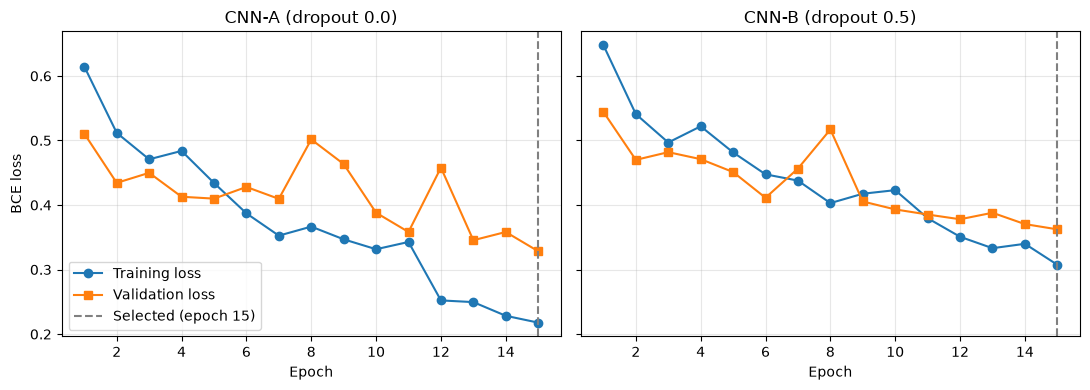

In [ ]:
cnn_b, hist_b, best_ep_b, time_b = train_cnn(dropout=0.5)
val_metrics_b = defect_metrics(y_val, (predict_probs(cnn_b, val_dataset) >= THRESHOLD).astype(int))
print(f"CNN-B (dropout 0.5): best epoch {best_ep_b}, time {time_b:.1f}s")
print({k: round(v, 4) for k, v in val_metrics_b.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, h, ep, title in [(axes[0], hist_a, best_ep_a, "CNN-A (dropout 0.0)"),
                         (axes[1], hist_b, best_ep_b, "CNN-B (dropout 0.5)")]:
    xs = range(1, EPOCHS + 1)
    ax.plot(xs, h["train_loss"], marker="o", label="Training loss")
    ax.plot(xs, h["val_loss"], marker="s", label="Validation loss")
    ax.axvline(ep, color="gray", linestyle="--", label=f"Selected (epoch {ep})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("BCE loss"); axes[0].legend()
plt.tight_layout(); plt.show()

In [ ]:
for name, h in [("CNN-A (dropout 0.0)", hist_a), ("CNN-B (dropout 0.5)", hist_b)]:
    tr, va = h["train_loss"][-1], h["val_loss"][-1]
    print(f"{name}: train loss {tr:.4f} | val loss {va:.4f} | gap {va - tr:.4f}")

CNN-A (dropout 0.0): train loss 0.2178 | val loss 0.3284 | gap 0.1106
CNN-B (dropout 0.5): train loss 0.3074 | val loss 0.3623 | gap 0.0549


### Interpretation of the Controlled Experiment (Dropout 0.0 vs. 0.5)

Only `dropout` changed (`CNN-A`: `0.0`, `CNN-B`: `0.5`); the split, preprocessing, architecture, optimizer, learning rate, batch size, epochs (`15`), and seed (`770`) were held fixed.

| Model | Precision | Recall | F1 | Accuracy | Last Train Loss | Last Val Loss | Gap |
|---|---|---|---|---|---|---|---|
| CNN-A (dropout 0.0) | 0.9252 | 0.8462 | 0.8839 | 0.8667 | 0.2178 | 0.3284 | 0.1106 |
| CNN-B (dropout 0.5) | 0.8167 | 0.8376 | 0.8270 | 0.7897 | 0.3074 | 0.3623 | 0.0549 |

**Expectation vs. result:** The outcome matched our expectation in loss behavior: adding `dropout=0.5` raised training loss (`0.2178` to `0.3074`), narrowed the train/validation loss gap (`0.1106` to `0.0549`), and left validation loss slightly higher (`0.3284` to `0.3623`) at epoch 15. Validation recall dropped slightly (`0.8462` to `0.8376`), while precision dropped sharply (`0.9252` to `0.8167`), lowering validation F1 by `0.0569` (`0.8839` to `0.8270`).

**Observations:** Regularizing a small 15-epoch CNN that was not yet overfitting slowed optimization and increased false positives (acceptable castings flagged as defective). Because CNN-B's validation loss was still declining at epoch 15, it would likely need more epochs rather than stronger regularization in this configuration.

**Caveat:** This comparison uses one seed (`770`) and one 195-image validation split, so it reflects performance under this fixed 15-epoch budget.

## 5. Model Selection and Test Evaluation

### Fair Model Selection (Validation F1, Threshold >= 0.5)

In [ ]:
# generate validation predictions for all three configurations using the fixed threshold (0.5)
lr_probs = log_reg.predict_proba(X_val_flat)[:, 1]
lr_preds = (lr_probs >= THRESHOLD).astype(int)

cnn_a_probs = predict_probs(cnn_a, val_dataset)
cnn_a_preds = (cnn_a_probs >= THRESHOLD).astype(int)

cnn_b_probs = predict_probs(cnn_b, val_dataset)
cnn_b_preds = (cnn_b_probs >= THRESHOLD).astype(int)

# package evaluation metrics and training times
models_eval = {
    "Baseline (Logistic Regression)": {
        "metrics": defect_metrics(y_val, lr_preds),
        "train_time": lr_train_time,
        "is_simpler": True  # LR is simpler than CNNs
    },
    "CNN-A (dropout 0.0)": {
        "metrics": defect_metrics(y_val, cnn_a_preds),
        "train_time": time_a,
        "is_simpler": False
    },
    "CNN-B (dropout 0.5)": {
        "metrics": defect_metrics(y_val, cnn_b_preds),
        "train_time": time_b,
        "is_simpler": False
    }
}

# all validation f1 scores (defective)
f1_summary = pd.DataFrame(
    [
        {
            "Configuration": name,
            "Validation F1 (Defective = 1)": round(info["metrics"]["F1"], 4)
        }
        for name, info in models_eval.items()
    ]
)

print("Validation F1 Scores for Defective Class (Threshold >= 0.5):")
display(f1_summary)

# select model using validation F1 for the defective class (break ties using simpler model)
best_name = None
best_f1 = -1.0
best_is_simpler = False

for name, info in models_eval.items():
    f1 = info["metrics"]["F1"]
    is_simpler = info["is_simpler"]

    if f1 > best_f1:
        best_f1 = f1
        best_name = name
        best_is_simpler = is_simpler
    elif abs(f1 - best_f1) < 1e-6:
        if is_simpler and not best_is_simpler:
            best_name = name
            best_f1 = f1
            best_is_simpler = is_simpler

print(f"\n[Selection Result] Best Model: {best_name} (Validation F1 Defective = {best_f1:.4f})")

Validation F1 Scores for Defective Class (Threshold >= 0.5):


,Configuration,Validation F1 (Defective = 1)
0,Baseline (Logistic Regression),0.8621
1,CNN-A (dropout 0.0),0.8839
2,CNN-B (dropout 0.5),0.8270



[Selection Result] Best Model: CNN-A (dropout 0.0) (Validation F1 Defective = 0.8839)


### Validation Comparison Table, Frozen Test Evaluation, and Error Examples

,Configuration,Precision (Defective),Recall (Defective),F1 (Defective),Accuracy,Training Time (s)
0,Baseline (Logistic Regression),0.8696,0.8547,0.8621,0.8359,1.56
1,CNN-A (dropout 0.0),0.9252,0.8462,0.8839,0.8667,23.57
2,CNN-B (dropout 0.5),0.8167,0.8376,0.8270,0.7897,23.50



Final Test Metrics:
  Precision: 0.9646
  Recall: 0.9316
  F1: 0.9478
  Accuracy: 0.9385




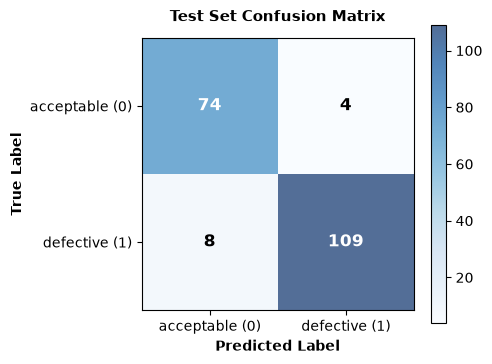


Error Analysis Summary:
  Total Test Samples: 195
  Misclassified Count: 12 (False Positives: 4, False Negatives: 8)
  Correct Count: 183



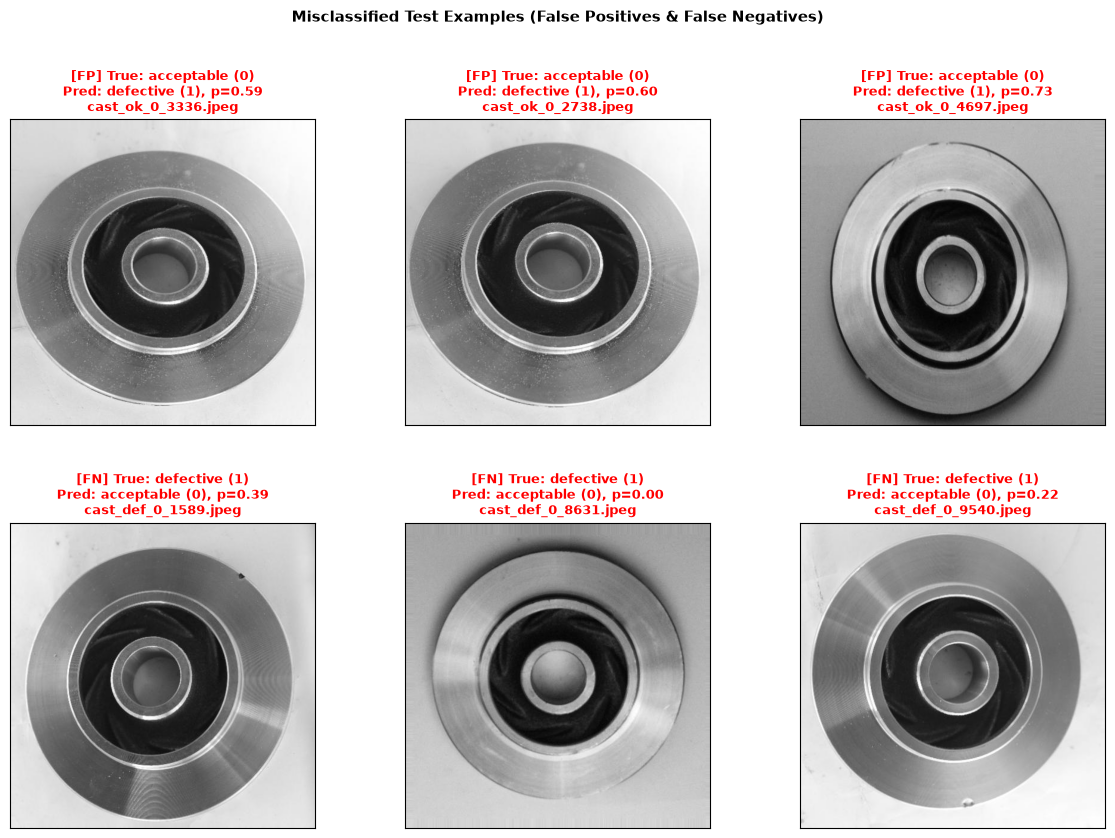

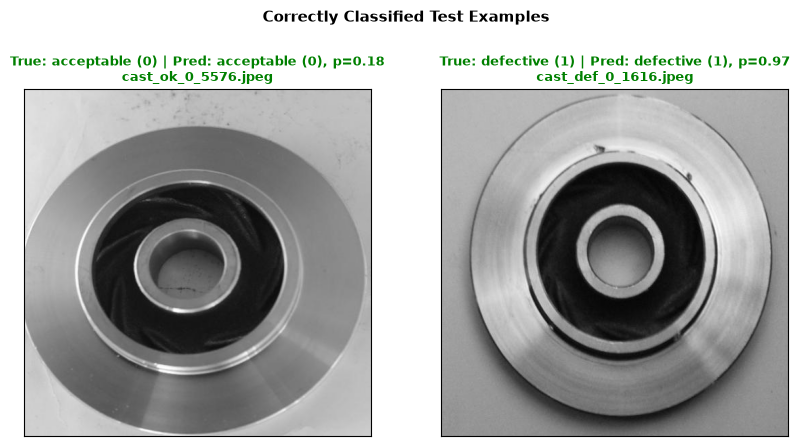

In [ ]:
# create and display the validation comparison table
val_table_data = []
for name, info in models_eval.items():
    m = info["metrics"]
    val_table_data.append({
        "Configuration": name,
        "Precision (Defective)": f"{m['Precision']:.4f}",
        "Recall (Defective)": f"{m['Recall']:.4f}",
        "F1 (Defective)": f"{m['F1']:.4f}",
        "Accuracy": f"{m['Accuracy']:.4f}",
        "Training Time (s)": f"{info['train_time']:.2f}"
    })

val_comparison_df = pd.DataFrame(val_table_data)
display(val_comparison_df)

# generate test predictions based on the selected model using the fixed threshold (0.5)
if "Baseline" in best_name:
    test_probs = log_reg.predict_proba(X_test_flat)[:, 1]
    test_preds = (test_probs >= THRESHOLD).astype(int)
elif "CNN-A" in best_name:
    test_probs = predict_probs(cnn_a, test_dataset)
    test_preds = (test_probs >= THRESHOLD).astype(int)
else:
    test_probs = predict_probs(cnn_b, test_dataset)
    test_preds = (test_probs >= THRESHOLD).astype(int)

# compute final test metrics for the defective class
test_metrics = defect_metrics(y_test, test_preds)
print("\nFinal Test Metrics:")
for k, v in test_metrics.items():
    print(f"  {k}: {v:.4f}")
print("\n")

# compute and display confusion matrix with labeled axes
cm = confusion_matrix(y_test, test_preds, labels=[ACCEPTABLE, DEFECTIVE])
fig, ax = plt.subplots(figsize=(5, 4))
cax = ax.matshow(cm, cmap=plt.cm.Blues, alpha=0.7)
fig.colorbar(cax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.xaxis.set_ticks_position("bottom")
ax.set_xticklabels([f"{CLASS_NAMES[ACCEPTABLE]} (0)", f"{CLASS_NAMES[DEFECTIVE]} (1)"])
ax.set_yticklabels([f"{CLASS_NAMES[ACCEPTABLE]} (0)", f"{CLASS_NAMES[DEFECTIVE]} (1)"])
ax.set_xlabel("Predicted Label", fontweight="bold")
ax.set_ylabel("True Label", fontweight="bold")
ax.set_title("Test Set Confusion Matrix", fontsize=11, fontweight="bold", pad=12)

for (i, j), val in np.ndenumerate(cm):
    ax.text(j, i, f"{val}", ha="center", va="center", fontsize=12, fontweight="bold",
            color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

# display up to 6 misclassified test images (ensuring both FP and FN if available) and 2 correctly classified images
misclassified_idx = np.where(y_test != test_preds)[0]
correct_idx = np.where(y_test == test_preds)[0]
fp_idx = np.where((y_test == ACCEPTABLE) & (test_preds == DEFECTIVE))[0]
fn_idx = np.where((y_test == DEFECTIVE) & (test_preds == ACCEPTABLE))[0]

print("\nError Analysis Summary:")
print(f"  Total Test Samples: {len(y_test)}")
print(f"  Misclassified Count: {len(misclassified_idx)} (False Positives: {len(fp_idx)}, False Negatives: {len(fn_idx)})")
print(f"  Correct Count: {len(correct_idx)}\n")

if len(misclassified_idx) <= 6:
    selected_errors = list(misclassified_idx)
elif len(fp_idx) > 0 and len(fn_idx) > 0:
    n_fp = min(3, len(fp_idx))
    n_fn = min(6 - n_fp, len(fn_idx))
    if n_fp + n_fn < 6:
        n_fp = min(6 - n_fn, len(fp_idx))
    selected_errors = list(fp_idx[:n_fp]) + list(fn_idx[:n_fn])
else:
    selected_errors = list(misclassified_idx[:6])

if len(selected_errors) > 0:
    rows = min(2, (len(selected_errors) + 2) // 3)
    cols = min(3, len(selected_errors))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.25 * rows))
    axes = np.array(axes).flatten() if len(selected_errors) > 1 else [axes]

    for i, idx in enumerate(selected_errors):
        ax = axes[i]
        row_data = test_df.iloc[idx]
        with Image.open(row_data["path"]) as im:
            ax.imshow(im)
        t_label = CLASS_NAMES[y_test[idx]]
        p_label = CLASS_NAMES[test_preds[idx]]
        err_type = "FP" if (y_test[idx] == ACCEPTABLE and test_preds[idx] == DEFECTIVE) else "FN"
        ax.set_title(
            f"[{err_type}] True: {t_label} ({y_test[idx]})\n"
            f"Pred: {p_label} ({test_preds[idx]}), p={test_probs[idx]:.2f}\n"
            f"{row_data['filename']}",
            color="red", fontsize=9, fontweight="bold"
        )
        ax.set_xticks([])
        ax.set_yticks([])

    for j in range(len(selected_errors), len(axes)):
        axes[j].axis("off")

    fig.suptitle("Misclassified Test Examples (False Positives & False Negatives)", fontsize=11, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.subplots_adjust(hspace=0.32)
    plt.show()
else:
    print("  Zero misclassified test examples found!")

# plot 2 correct examples (1 acceptable + 1 defective if both exist)
tn_idx = np.where((y_test == ACCEPTABLE) & (test_preds == ACCEPTABLE))[0]
tp_idx = np.where((y_test == DEFECTIVE) & (test_preds == DEFECTIVE))[0]
if len(tn_idx) > 0 and len(tp_idx) > 0:
    selected_correct = [int(tn_idx[0]), int(tp_idx[0])]
else:
    selected_correct = list(correct_idx[:2])

if len(selected_correct) >= 2:
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.5))
    for i, idx in enumerate(selected_correct):
        ax = axes[i]
        row_data = test_df.iloc[idx]
        with Image.open(row_data["path"]) as im:
            ax.imshow(im)
        t_label = CLASS_NAMES[y_test[idx]]
        p_label = CLASS_NAMES[test_preds[idx]]
        ax.set_title(
            f"True: {t_label} ({y_test[idx]}) | Pred: {p_label} ({test_preds[idx]}), p={test_probs[idx]:.2f}\n"
            f"{row_data['filename']}",
            color="green", fontsize=9, fontweight="bold"
        )
        ax.set_xticks([])
        ax.set_yticks([])

    fig.suptitle("Correctly Classified Test Examples", fontsize=11, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

# Part 5 Explanations:

**False negatives** are products that are defective, but the model labels them as acceptable.

**False Positives** are products that are acceptable, but the model labels them as defective.

_________________

**Which matters more for inspection workflow?**

False negatives would be more important because a high false negative rate would mean more defective products reach customers. This would affect the business's reputation and hurt customer retention. Depending on the type of product, this could also result in safety and reliability concerns if more defective products reach customers.
The tradeoff would be having higher false positives -- resulting in higher manufacturing costs (more waste).
_________________

**Limitations**:
While controlled images should help support claims about a new factory or product, these do not guarantee the model will perform as expected. Small variances could have a high impact on performance. Another limitation is the size of the images. Resizing the images to be smaller may have caused the model to miss certain patterns, constraining the model on how well it generalizes rarer defects that may not have been seen often in such a small dataset.

## 6. Conclusions

- **Data Audit & Split:** All `1,300` original `512 x 512` images (`519` acceptable, `781` defective) passed integrity and duplicate checks with `0` exclusions and were split cleanly into `910` train / `195` validation / `195` test images (`seed=770`) using identical `64 x 64` grayscale `[0, 1]` preprocessing.
- **Model Comparison & Selection:** On validation F1 for the defective class at fixed threshold `0.5`, **CNN-A (dropout 0.0)** (`F1 = 0.8839`) outperformed both the Logistic Regression baseline (`F1 = 0.8621`) and regularized `CNN-B (dropout 0.5)` (`F1 = 0.8270`).
- **Frozen Test Performance:** Evaluated once on the held-out `195`-image test set, **CNN-A (dropout 0.0)** achieved Precision `0.9646`, Recall `0.9316`, F1 `0.9478`, and Accuracy `0.9385` (`183` correct, `12` misclassified: `4` false positives and `8` false negatives).